![Python Banner](../../Image/05_01_tree_based_models.png)


# 1.7 Instrumental Causal XGBoost (Boosted IV Forest)


## Overview

A **Boosted IV Forest** estimates heterogeneous treatment effects in settings where treatment assignment is endogenous — that is, correlated with unobserved factors that also affect the outcome. Like a standard Instrumental Forest, it exploits an **instrumental variable** $Z$ that shifts treatment $W$ without directly affecting the outcome $Y$. The "boosted" part is the first stage. Cross-fitted XGBoost models estimate the outcome mean, the treatment mean, and the instrument mean, which lets the nuisance functions pick up nonlinearities and interactions. The second stage fits two more boosters to the residual products and returns their ratio as the conditional LATE.

The result is a two-stage estimator: XGBoost estimates the nuisances on tabular covariates, and a residual Wald ratio turns those residuals into a conditional LATE.

### The Conditional LATE

The quantity of interest is the **Conditional Local Average Treatment Effect (LATE)** — the treatment effect for *compliers* (units whose treatment status changes because of $Z$), allowed to vary with covariates:

$$\tau(X) = \frac{\text{Cov}[Y - \hat{m}(X),\; Z - \hat{p}(X) \mid X]}{\text{Cov}[W - \hat{e}(X),\; Z - \hat{p}(X) \mid X]}$$

where the three nuisance functions are:

-   $\hat{m}(X) = E[Y \mid X]$ — the conditional mean outcome, estimated to partial out baseline variation in $Y$;
-   $\hat{e}(X) = E[W \mid X]$ — the treatment propensity, estimated to partial out selection into treatment;
-   $\hat{p}(X) = E[Z \mid X]$ — the instrument propensity, estimated to partial out any covariate-driven variation in $Z$.

After residualizing, the numerator $\text{Cov}[\tilde{Y}, \tilde{Z} \mid X]$ captures how much the instrument moves the outcome; the denominator $\text{Cov}[\tilde{W}, \tilde{Z} \mid X]$ captures how much the instrument moves the treatment. Their ratio isolates the local causal effect of $W$ on $Y$ — purged of confounding — for the complier subpopulation with covariates $X = x$.

### Why "Boosted"?

A standard instrumental forest estimates $\hat{m}$, $\hat{e}$, and $\hat{p}$ using regression forests (or skips nuisance estimation entirely if the instrument is assumed randomized). This works well when nuisance functions are smooth and additive, but can underfit when outcomes and treatments depend on complex interactions between covariates.

Replacing the first stage with **cross-fitted C-XGBoost** addresses this directly:

-   XGBoost captures irregular boundaries, high-order interactions, and nonlinear feature effects that regression forests can miss.
-   **Cross-fitting** (k-fold out-of-sample prediction) prevents the nuisance estimates from overfitting to the training data, which would otherwise inflate the apparent signal in the residuals and bias the second-stage LATE estimates.
-   The second stage is a residual Wald ratio on $(\tilde{Y}, \tilde{W}, \tilde{Z}, X)$: one booster fits the outcome–instrument product and another fits the treatment–instrument product. The conditional LATE is their ratio.

The theoretical justification is the **Neyman orthogonality** of the IV moment condition: the LATE estimator is locally insensitive to small errors in nuisance estimation, meaning flexible first-stage models improve finite-sample performance without introducing asymptotic bias, as long as nuisances converge at a reasonable rate.

### Validity Conditions

The Boosted IV Forest inherits the standard IV assumptions:

-   **Relevance** — $Z$ must be a strong predictor of $W$ conditional on $X$. Weak instruments inflate the variance of $\tau(X)$ and can cause severe bias. A first-stage regression below reports the instrument coefficient and its F-statistic.
-   **Exclusion restriction** — $Z$ affects $Y$ only through $W$, with no direct path. This is not testable from data and must be justified by domain knowledge.
-   **Independence** — $Z$ is as good as randomly assigned conditional on $X$ (no unmeasured confounders of the $Z \to Y$ path).

### Pipeline: Five Steps

![Boosted IV Forest pipeline](../../Image/boosted_IV_forest.png)

A few things worth highlighting from the pipeline:

**Step 2 (cross-fitting) is the critical upgrade over a standard instrumental forest.** Fitting nuisance models on the full training set and then predicting on the same data induces overfitting into the residuals — the residuals appear smaller than they should be, which inflates the apparent signal in the IV covariance. K-fold cross-fitting breaks this feedback loop by ensuring every nuisance prediction is made out-of-sample. The theoretical grounding is **Neyman orthogonality**: the IV moment condition is locally insensitive to small errors in $\hat{m}$, $\hat{e}$, and $\hat{p}$, so cross-fitted nuisances at a moderate convergence rate are sufficient for root-$n$ inference on $\tau(X)$.

**Step 3 is where the nuisance models meet the causal target.** The residuals $(\tilde{Y}, \tilde{W}, \tilde{Z})$ remove variation in $Y$, $W$, and $Z$ that can be explained by $X$. The boosted second stage then estimates where $\text{Cov}[\tilde{Y}, \tilde{Z}] / \text{Cov}[\tilde{W}, \tilde{Z}]$ differs across covariate profiles.

**The first-stage F-statistic in step 4 is not optional.** A weak instrument ($F < 10$ is a common rule of thumb) means $Z$ explains little variation in $W$ after partialling out $X$, which causes the denominator $\text{Cov}[\tilde{W}, \tilde{Z} \mid X]$ to be near zero. The resulting LATE estimates become extremely noisy and potentially severely biased — the XGBoost first stage cannot rescue a fundamentally weak instrument.

### Key Features

-   **Endogeneity correction**: Instrument $Z$ isolates exogenous variation in $W$.
-   **Heterogeneous effects**: LATE $\tau(X)$ varies with covariates.
-   **Flexible first stage**: XGBoost nuisances can capture nonlinearities; cross-fitting avoids overfitting.
-   **Instrument diagnostics**: a first-stage regression and its F-statistic.
-   **Subgroup summaries**, **variable importance**, and **SHAP** explanations of the fitted LATE.



## Boosted IV Forest with Python

This tutorial uses the **Card (1995)** dataset to estimate **returns to education** (effect of education on log wages) using **proximity to a 4-year college** as an instrument, implemented with the `BoostedIVForest` class from PyCausalML.


## Setup

This notebook fits **`BoostedIVForest`** from **[PyCausalML](https://github.com/zia207/PyCausalML)** (`pycausalml.tree_based_models`).

`fit(X, treatment, y, instrument)` returns the fitted estimator. `predict` returns a NumPy array of conditional average treatment effects. A fitted model also exposes `explain` and `plot_shap`.

Install the package from this repository, with the plotting and boosting extras.

The example is the Card (1995) extract used in the instrumental forest tutorial: log wage, years of education, and proximity to a four-year college. `learner='xgb'` uses XGBoost for the residual Wald estimator.


In [1]:
import subprocess
import sys
from pathlib import Path

def _repo_root() -> Path:
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        if (cand / "pyproject.toml").is_file() and (cand / "src" / "pycausalml").is_dir():
            return cand
    raise FileNotFoundError(
        "PyCausalML repository was not found. Run this notebook from the repository."
    )

root = _repo_root()
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q", "-e", f"{root}[plot,boost,shap]", "statsmodels",
])
print("PyCausalML ready.")


PyCausalML ready.


In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm

from pycausalml import BoostedIVForest

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
print("Imported PyCausalML")


Imported PyCausalML


## Data: Returns to Education (Card Dataset)

We estimate the causal effect of **education on wages** using proximity to a four-year college as an instrument (Card, 1995).

- `lwage` = log(wage) — outcome (Y)
- `educ` = years of education — endogenous treatment (W)
- `nearc4` = grew up near a four-year college — instrument (Z)
- `exper` = potential work experience
- `expersq` = experience squared
- `black` = Black
- `smsa` = lives in an SMSA
- `south` = lives in the South

### Load and Prepare Data

In [3]:
import os
import tempfile
import urllib.request

card_url = "https://github.com/dmarcelinobr/Datasets/raw/refs/heads/master/CARD.DTA"
with tempfile.NamedTemporaryFile(delete=False, suffix=".dta") as tmp:
    urllib.request.urlretrieve(card_url, tmp.name)
    card = pd.read_stata(tmp.name)
os.unlink(tmp.name)

card["exper"] = card["exper"].astype(float)
card["expersq"] = card["exper"] ** 2
card = card[["lwage", "educ", "nearc4", "exper", "expersq", "black", "smsa", "south"]].dropna()

feature_names = ["exper", "expersq", "black", "smsa", "south"]
X = card[feature_names].to_numpy(dtype=float)
Y = card["lwage"].to_numpy(dtype=float)
W = card["educ"].to_numpy(dtype=float)
Z = card["nearc4"].to_numpy(dtype=float)
print(card.head())
print("N =", len(card))


      lwage  educ  nearc4  exper  expersq  black  smsa  south
0  6.306275     7       0   16.0    256.0      1     1      0
1  6.175867    12       0    9.0     81.0      0     1      0
2  6.580639    12       0   16.0    256.0      0     1      0
3  5.521461    11       1   10.0    100.0      0     1      0
4  6.591674    12       1   16.0    256.0      0     1      0
N = 3010


### Descriptive Statistics and First-Stage Check

In [4]:
first_stage = smf.ols(
    "educ ~ nearc4 + exper + expersq + black + smsa + south", data=card
).fit()
print(first_stage.summary().tables[1].as_text())
anova_res = anova_lm(first_stage, typ=2)
print(f"F-statistic for nearc4: {anova_res.loc['nearc4', 'F']:.2f}")
print(f"First-stage overall F-statistic: {first_stage.fvalue:.2f}")


                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     16.6592      0.176     94.446      0.000      16.313      17.005
nearc4         0.3373      0.083      4.089      0.000       0.176       0.499
exper         -0.4100      0.034    -12.169      0.000      -0.476      -0.344
expersq        0.0007      0.002      0.444      0.657      -0.003       0.004
black         -1.0061      0.090    -11.224      0.000      -1.182      -0.830
smsa           0.4039      0.085      4.758      0.000       0.237       0.570
south         -0.2915      0.079     -3.679      0.000      -0.447      -0.136
F-statistic for nearc4: 16.72
First-stage overall F-statistic: 451.87


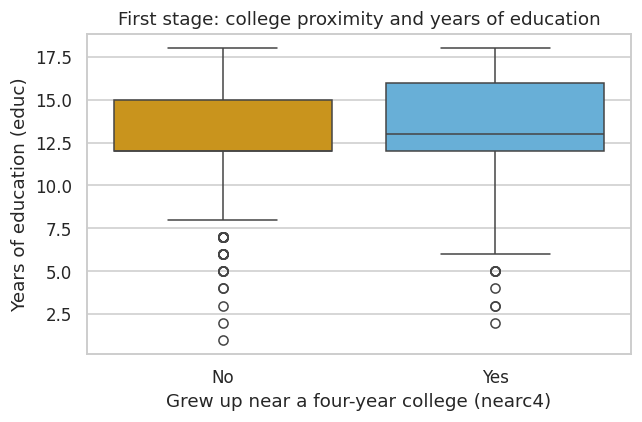

In [5]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.boxplot(
    data=card,
    x="nearc4",
    y="educ",
    hue="nearc4",
    palette=["#E69F00", "#56B4E9"],
    legend=False,
    ax=ax,
)
ax.set_title("First stage: college proximity and years of education")
ax.set_xlabel("Grew up near a four-year college (nearc4)")
ax.set_ylabel("Years of education (educ)")
ax.set_xticks([0, 1], ["No", "Yes"])
fig.tight_layout()
plt.show()


### Training a Boosted IV Forest

`BoostedIVForest` cross-fits XGBoost nuisances for log wage, years of education, and college proximity, then forms the conditional return to schooling from the residual Wald ratio. Education is continuous, as in the usual Card specification.


In [6]:
model = BoostedIVForest(n_estimators=60, n_splits=2, learner="xgb", random_state=1)
model.fit(X, W, Y, Z, feature_names=feature_names)
tau_hat = model.predict(X)
print("BoostedIVForest")
print(f"  n = {len(tau_hat)}, p = {X.shape[1]}")
print(f"  mean CATE = {tau_hat.mean():.3f}")
print(f"  CATE sd = {tau_hat.std():.3f}")


BoostedIVForest
  n = 3010, p = 5
  mean CATE = 0.090
  CATE sd = 0.215


### Model Summary

In [7]:
print(f"Mean estimated LATE: {tau_hat.mean():.3f}")
print(f"LATE sd: {tau_hat.std():.3f}")
print(f"LATE range: {tau_hat.min():.3f} to {tau_hat.max():.3f}")


Mean estimated LATE: 0.090
LATE sd: 0.215
LATE range: -1.101 to 2.164


### Predicting Treatment Effects

In [8]:
ate_hat = float(tau_hat.mean())
se_hat = float(tau_hat.std(ddof=1) / np.sqrt(len(tau_hat)))
print(f"Average estimated return to education: {ate_hat:.3f} (SE of the mean {se_hat:.3f})")


Average estimated return to education: 0.090 (SE of the mean 0.004)


### Visualizing Results

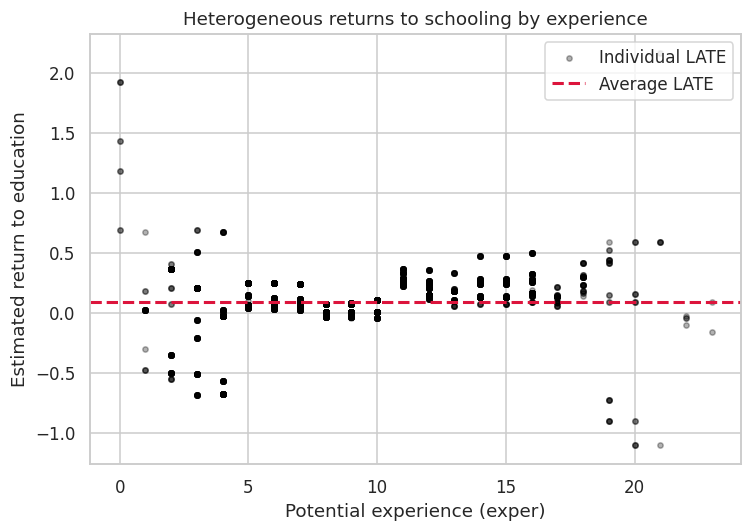

In [9]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(card["exper"], tau_hat, s=12, alpha=0.3, c="black", label="Individual LATE")
ax.axhline(ate_hat, color="crimson", lw=2, ls="--", label="Average LATE")
ax.set_xlabel("Potential experience (exper)")
ax.set_ylabel("Estimated return to education")
ax.set_title("Heterogeneous returns to schooling by experience")
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()


### CATE Distribution and Partial Dependence

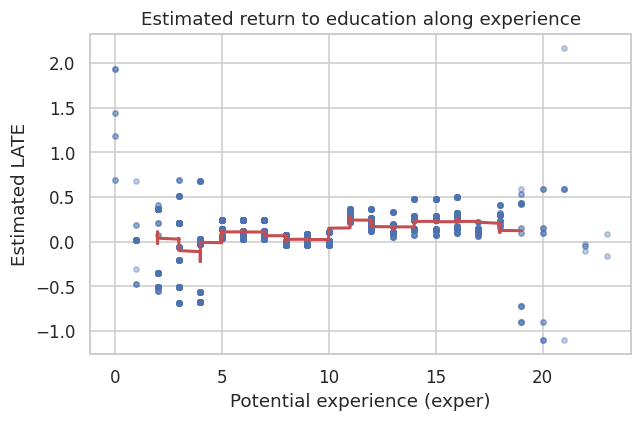

In [10]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(card["exper"], tau_hat, s=12, alpha=0.35, c="#4C72B0")
order = np.argsort(card["exper"].to_numpy())
window = max(20, len(order) // 30)
kernel = np.ones(window) / window
smooth = np.convolve(tau_hat[order], kernel, mode="valid")
xs = card["exper"].to_numpy()[order][window // 2: window // 2 + len(smooth)]
ax.plot(xs, smooth, color="#C44E52", lw=2)
ax.set_xlabel("Potential experience (exper)")
ax.set_ylabel("Estimated LATE")
ax.set_title("Estimated return to education along experience")
fig.tight_layout()
plt.show()


### Predicting for New Data

In [11]:
new_data = pd.DataFrame({
    "exper": [10],
    "expersq": [10 ** 2],
    "black": [0],
    "smsa": [1],
    "south": [0],
})
new_pred = model.predict(new_data[feature_names].to_numpy())
print(
    "Predicted return to education for this profile:",
    round(float(np.squeeze(new_pred)), 3),
)


Predicted return to education for this profile: 0.01


### Subgroup Analysis

In [12]:
rows = []
for name in feature_names:
    col = card[name].to_numpy(dtype=float)
    levels = np.unique(col)
    if len(levels) == 2:
        groups = [(f"{name} = {level:g}", col == level) for level in levels]
    else:
        cut = float(np.median(col))
        groups = [(f"{name} <= {cut:g}", col <= cut), (f"{name} > {cut:g}", col > cut)]
    for label, mask in groups:
        rows.append({
            "group": label,
            "n": int(mask.sum()),
            "mean_late": float(tau_hat[mask].mean()),
        })
print(pd.DataFrame(rows).round(3).to_string(index=False))


        group    n  mean_late
   exper <= 8 1578      0.048
    exper > 8 1432      0.136
expersq <= 64 1578      0.048
 expersq > 64 1432      0.136
    black = 0 2307      0.098
    black = 1  703      0.062
     smsa = 0  864      0.120
     smsa = 1 2146      0.078
    south = 0 1795      0.080
    south = 1 1215      0.104


### Variable Importance

   feature  importance
1  expersq       0.000
4    south       0.110
0    exper       0.222
3     smsa       0.234
2    black       0.434


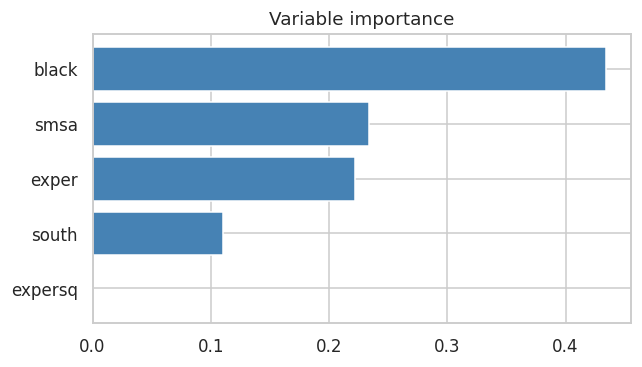

In [13]:
vi = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importance(),
}).sort_values("importance")
print(vi.round(3))
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.barh(vi["feature"], vi["importance"], color="steelblue")
ax.set_title("Variable importance")
fig.tight_layout()
plt.show()


### Estimated LATE and experience

Both potential outcomes are not observed, so this is a description of the fitted surface: a linear regression of the estimated return to education on potential experience.

In [14]:
design = np.column_stack([np.ones(len(tau_hat)), card["exper"].to_numpy()])
beta, _, _, _ = np.linalg.lstsq(design, tau_hat, rcond=None)
print(pd.DataFrame({
    "term": ["intercept", "exper"],
    "estimate": beta,
}).round(4))


        term  estimate
0  intercept   -0.0295
1      exper    0.0135


### SHAP values for the conditional LATE

SHAP array shape: (40, 5)


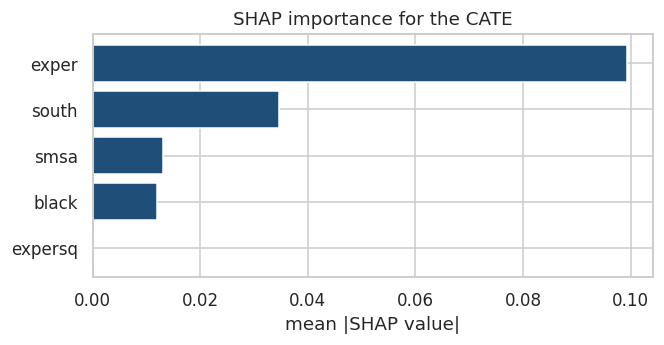

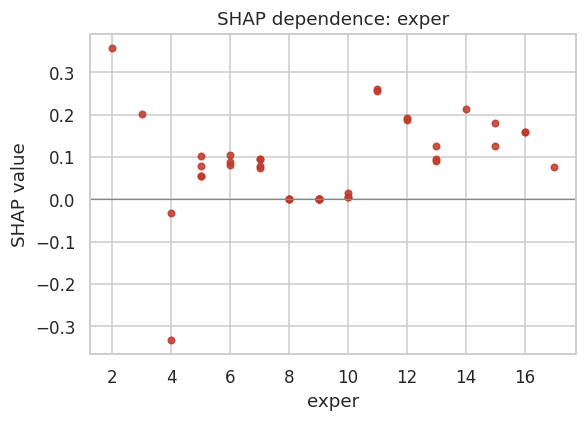

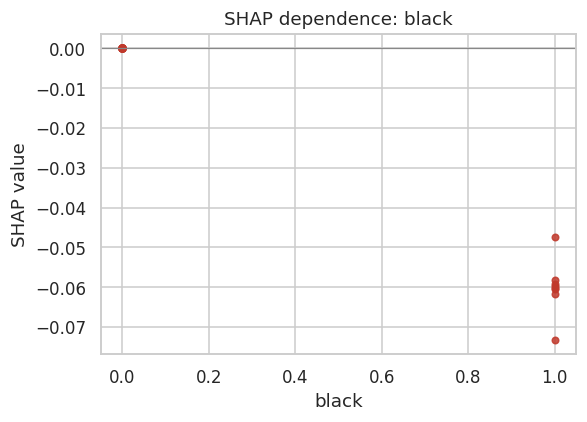

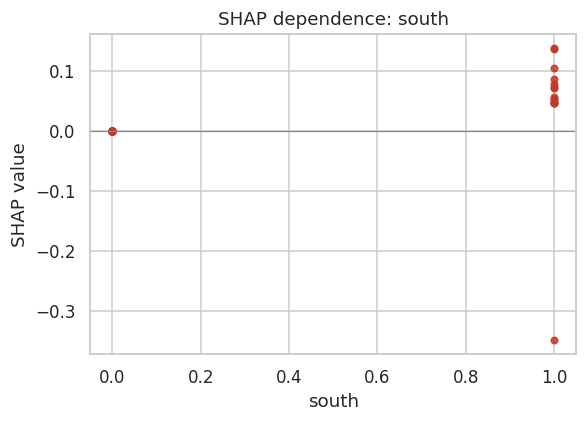

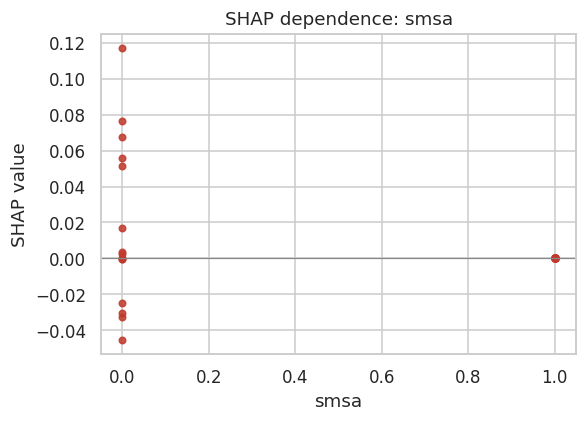

In [15]:
sv = model.explain(X, max_samples=40, random_state=42)
print("SHAP array shape:", sv.values.shape)
sv.plot_importance()
plt.show()
for feature in ["exper", "black", "south", "smsa"]:
    sv.plot_dependence(feature)
    plt.show()


> **Note:**
> -   Check first-stage F-statistic \> 10 (strong instrument).
> -   Verify instrument validity (relevance and exclusion restriction) in your application.
> -   Increase `n_splits` and `n_estimators` for a more stable fit.

## Summary and Conclusion

**Boosted IV Forest** estimates a heterogeneous local average treatment effect when treatment is endogenous. Cross-fitted XGBoost models residualize the outcome, treatment, and instrument, and a second pair of boosters forms the conditional LATE as a residual Wald ratio. This tutorial used the Card (1995) dataset, with years of education as the treatment and proximity to a four-year college as the instrument, and walked through `BoostedIVForest`: the first stage, fitted LATEs, a new-profile prediction, subgroup summaries, variable importance, and SHAP explanations. The same workflow applies to other settings with a valid instrument and covariates.

## Resources

1.  Athey, Susan, Julie Tibshirani, and Stefan Wager. "Generalized Random Forests." *Annals of Statistics*, 47(2), 2019.
2.  Card, David (1995). "Using Geographic Variation in College Proximity to Estimate the Return to Schooling." In *Aspects of Labour Market Behaviour: Essays in Honour of John Vanderkamp*.
3.  Wang, Guihua, et al. "An Instrumental Variable Forest Approach for Detecting Heterogeneous Treatment Effects in Observational Studies." *Management Science*, 2021.
4.  `BoostedIVForest` in PyCausalML.
